# 05 · Physical output

What the tracking says about running, and whether it agrees with SkillCorner's own pipeline.

In [1]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from src.config import DERIVED_DIR, PROCESSED_DIR, PALETTE
plt.style.use("dark_background")
plt.rcParams.update({
    "figure.facecolor": PALETTE["surface"], "axes.facecolor": PALETTE["surface"],
    "savefig.facecolor": PALETTE["surface"], "grid.color": PALETTE["grid"],
    "axes.edgecolor": PALETTE["line"], "text.color": PALETTE["text"],
    "axes.labelcolor": PALETTE["text_secondary"], "xtick.color": PALETTE["muted"],
    "ytick.color": PALETTE["muted"], "font.size": 9, "figure.dpi": 110,
})
pd.set_option("display.width", 140, "display.max_columns", 40)


In [2]:
phys = pd.read_parquet(DERIVED_DIR / "player_match_physical.parquet")
out = phys[(phys.tracked_minutes >= 45) & (phys.position != "GK")]
out[["tracked_minutes", "coverage", "total_distance_m", "m_per_min", "hsr_distance_m",
     "sprint_count", "psv99_ms", "top_speed_ms", "detected_frac"]].describe().round(2)

,tracked_minutes,coverage,total_distance_m,m_per_min,hsr_distance_m,sprint_count,psv99_ms,top_speed_ms,detected_frac
count,370.00,370.00,370.00,370.00,370.00,370.00,370.00,370.00,370.00
mean,67.28,0.75,8452.48,125.96,656.94,8.05,6.30,8.97,0.60
std,8.65,0.04,1206.16,11.43,244.01,4.80,0.42,1.16,0.10
min,45.65,0.64,5342.55,97.34,112.13,0.00,4.87,6.98,0.38
25%,59.88,0.73,7590.00,118.17,478.61,5.00,6.02,8.16,0.53
50%,71.23,0.75,8447.42,125.79,642.01,7.00,6.31,8.65,0.61
75%,73.74,0.77,9290.88,134.03,805.95,10.00,6.58,9.57,0.68
max,80.90,0.86,11813.29,155.99,1453.44,25.00,7.43,11.99,0.82


Coverage is the number to keep in view: the broadcast shows roughly 73% of the minutes a player was on the pitch, so these are distances *while visible*.

64% of player-matches cover more ground without the ball than with it


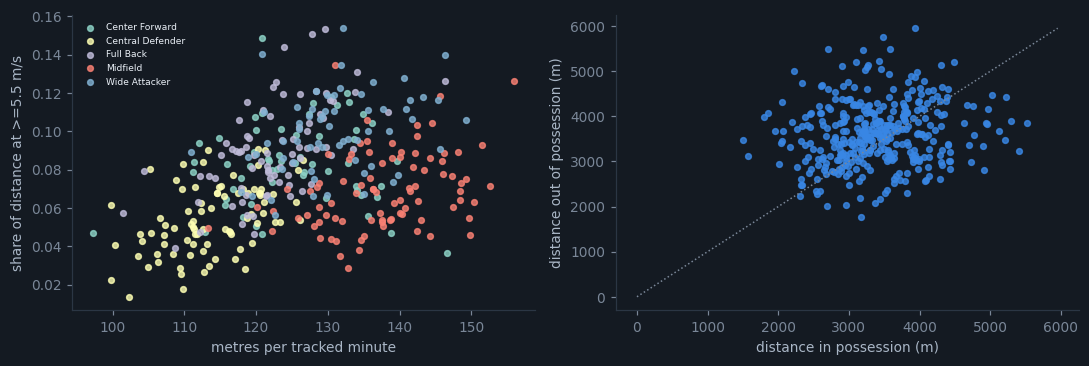

In [3]:
fig, ax = plt.subplots(1, 2, figsize=(10, 3.4))
for grp, sub in out.groupby("position_group", observed=True):
    ax[0].scatter(sub.m_per_min, sub.hsr_distance_m / sub.total_distance_m, s=14,
                  alpha=0.8, label=grp)
ax[0].set_xlabel("metres per tracked minute"); ax[0].set_ylabel("share of distance at >=5.5 m/s")
ax[0].legend(fontsize=6, frameon=False)
ax[1].scatter(out.distance_tip_m, out.distance_otip_m, s=14, alpha=0.8, color=PALETTE["accent"])
lim = [0, max(out.distance_tip_m.max(), out.distance_otip_m.max())]
ax[1].plot(lim, lim, ls=":", color=PALETTE["muted"], lw=1)
ax[1].set_xlabel("distance in possession (m)"); ax[1].set_ylabel("distance out of possession (m)")
for a in ax: a.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
print(f"{(out.distance_otip_m > out.distance_tip_m).mean():.0%} of player-matches cover more "
      "ground without the ball than with it")

## Cross-check against SkillCorner's own PSV99

n = 186 players in both tables
Pearson r = 0.58
mean offset = -5.1 km/h


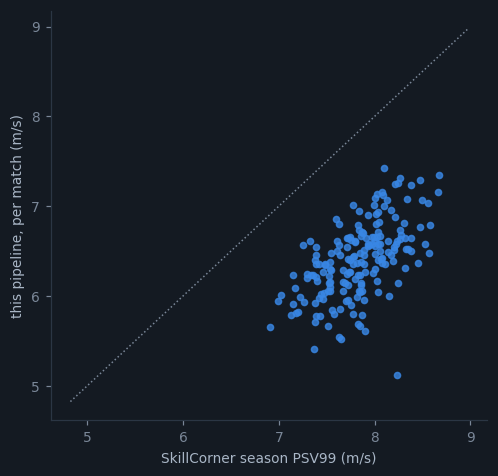

In [4]:
from src.config import REPORTS_DIR
r = pd.read_parquet(REPORTS_DIR / "research" / "q8_psv99_validation.parquet").dropna(
    subset=["fil_psv99_ms", "sc_psv99_ms"])
print(f"n = {len(r)} players in both tables")
print(f"Pearson r = {np.corrcoef(r.fil_psv99_ms, r.sc_psv99_ms)[0, 1]:.2f}")
print(f"mean offset = {r.diff_ms.mean() * 3.6:+.1f} km/h")
plt.figure(figsize=(4.6, 4.4))
plt.scatter(r.sc_psv99_ms, r.fil_psv99_ms, s=16, alpha=0.8, color=PALETTE["accent"])
lim = [min(r.sc_psv99_ms.min(), r.fil_psv99_ms.min()) - 0.3,
       max(r.sc_psv99_ms.max(), r.fil_psv99_ms.max()) + 0.3]
plt.plot(lim, lim, ls=":", color=PALETTE["muted"], lw=1)
plt.xlabel("SkillCorner season PSV99 (m/s)"); plt.ylabel("this pipeline, per match (m/s)")
plt.gca().spines[["top", "right"]].set_visible(False); plt.tight_layout()

The offset is expected: SkillCorner's figure is a season-level 99th percentile
from their full pipeline; this one covers one to three matches of broadcast
frames after deliberately conservative smoothing. The correlation is the
check, not the intercept.